# Klasifikasi Kesegaran Daun Tanaman Kampus (Topik 2)
**Mata Kuliah:** Pengolahan Citra Digital dan Visi Komputer (CIF61339) - Kelas A  
**Dosen Pengampu:** Yuita Arum Sari, S.Kom., M.Kom., Ph.D.  
**Fakultas Ilmu Komputer (FILKOM), Universitas Brawijaya**

**Kelompok Pengembang:**
1. Nadhif Rif'at Rasendriya (235150201111074) - *Data & PCD*
2. Nadhif Adita Fernanda (235150201111033) - *Feature & ML Klasik*
3. Muzhaffar Ammar (235150200111033) - *Deep Learning & CV*

---
### 🎯 Tujuan Notebook (Progress 1)
Notebook ini berfokus pada tahapan hulu (Tahap 0) dari pipeline terintegrasi kami:
1. **Pembuatan `manifest.csv`:** Membaca 127 foto primer dari Google Drive, mengekstrak metadata waktu (*timestamp* EXIF), dan mendeteksi file duplikat.
2. **Uji Reliabilitas Label:** Menghitung *Cohen's Kappa* paca-audit internal untuk membuktikan subjektivitas visual kelas transisi (Menguning vs Kering).
3. **Exploratory Data Analysis (EDA) Kilat:** Melakukan segmentasi *Otsu* awal, menganalisis distribusi ruang warna (HSV/LAB) piksel daun murni, serta melakukan **Uji Kebocoran Latar (*Background Patch Test*)** untuk mendeteksi *shortcut learning* pada sensor kamera/iluminasi.


## 1. Pembuatan Manifest, Cek Duplikat, & Inventaris Sesi
**Tujuan:** Membaca direktori Google Drive yang berisi dataset mentah (RAW), memetakan nama file menjadi metadata terstruktur (kelas awal, tanggal, jam, dan perkiraan pemotret), serta mendeteksi kemungkinan adanya file bernama ganda yang dapat mengacaukan proses *data splitting*.


In [ ]:
import os
import re
import cv2
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

DATASET_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset'
folder_map = {
    'P1_Sehat': 'Sehat',
    'P1_Menguning': 'Menguning',
    'P1_Kering': 'Kering'
}

records = []
seen_filenames = {}

for folder_name, label_awal in folder_map.items():
    folder_path = os.path.join(DATASET_DIR, folder_name)
    if not os.path.exists(folder_path):
        print(f"[PERINGATAN] Folder tidak ditemukan: {folder_path}")
        continue

    for fname in sorted(os.listdir(folder_path)):
        if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue

        fpath = os.path.join(folder_path, fname)
        img = cv2.imread(fpath)
        if img is None:
            continue
        h, w, _ = img.shape

        # Cek duplikat nama file (misal IMG_20261028_103125.jpg)
        is_duplicate = fname in seen_filenames
        seen_filenames[fname] = seen_filenames.get(fname, 0) + 1

        # Ekstrak tanggal & waktu dari nama file IMG_YYYYMMDD_HHMMSS
        match = re.search(r'(\d{8})_(\d{6})', fname)
        if match:
            date_str, time_str = match.group(1), match.group(2)
            sesi = 1 if date_str == '20261022' else (2 if date_str == '20261028' else 0)
            cahaya = 'Mendung_Merata' if sesi == 1 else 'Pagi_Hari'
        else:
            date_str, time_str, sesi, cahaya = 'Unknown', 'Unknown', 0, 'Unknown'

        # Perkiraan pemotret awal berdasarkan inventaris sesi & kelas (konfirmasi di tim)
        if sesi == 1:
            pemotret = 'Muzhaffar' if label_awal == 'Sehat' else ('Nadhif_Rifat' if label_awal == 'Menguning' else 'Nadhif_Adita')
        else:
            pemotret = 'Rifat_atau_Adita' if label_awal == 'Sehat' else ('Muzhaffar' if label_awal == 'Menguning' else 'Nadhif_Rifat')

        records.append({
            'id_foto': f"{label_awal[:1]}_{len(records)+1:03d}",
            'filename': fname,
            'filepath': fpath,
            'label_awal': label_awal,
            'anotator_1': label_awal,   # Diisi saat audit independen anggota 1
            'anotator_2': label_awal,   # Diisi saat audit independen anggota 2
            'label_final': label_awal,  # Diisi hasil konsensus (Sehat/Menguning/Kering/Borderline)
            'sesi': sesi,
            'tanggal': date_str,
            'waktu': time_str,
            'pemotret': pemotret,
            'hp': f"HP_{pemotret}",
            'cahaya': cahaya,
            'resolusi': f"{w}x{h}",
            'duplikat_nama': is_duplicate
        })

df_manifest = pd.DataFrame(records)
df_manifest.to_csv('manifest.csv', index=False)

print(f"Total foto terbaca: {len(df_manifest)}")
print("\n--- Rekapitulasi Sesi x Kelas (Pra-Audit) ---")
print(pd.crosstab(df_manifest['sesi'], df_manifest['label_awal'], margins=True))

print("\n--- Cek File dengan Nama Ganda ---")
dups = [k for k, v in seen_filenames.items() if v > 1]
print("File nama ganda:", dups if dups else "Tidak ditemukan")

Mounted at /content/drive
Total foto terbaca: 127

--- Rekapitulasi Sesi x Kelas (Pra-Audit) ---
label_awal  Kering  Menguning  Sehat  All
sesi                                     
1               23         40     22   85
2               12         11     19   42
All             35         51     41  127

--- Cek File dengan Nama Ganda ---
File nama ganda: ['IMG_20261022_155402.jpg']


### Analisis Keluaran Sel 1:
- **Total Dataset:** Terdeteksi 127 foto yang berhasil dibaca.
- **Konfound Sesi & Cahaya:** Terlihat ketidakseimbangan perbandingan kelas per sesi. Sesi 1 (mendung) menyumbang 85 foto, sedangkan Sesi 2 (pagi) menyumbang 42 foto. Kelas Sehat sangat bergantung pada Sesi 2, memunculkan risiko model menghafal cahaya.
- **Deteksi Duplikat:** Ditemukan 1 file dengan nama ganda (`IMG_20261022_155402.jpg`). File ini wajib dibersihkan atau diganti namanya sebelum masuk ke tahap pembagian dataset (*K-Fold split*).


## 2. Perhitungan Reliabilitas Label (Cohen's Kappa)
**Tujuan:** Kasus transisi antara daun "Menguning" dan "Kering" sangat rawan terhadap subjektivitas pelabelan (berdasarkan kelenturan fisik di lapangan vs persentase warna visual). Sel ini mengukur tingkat kesepakatan antar label menggunakan metrik statisik *Cohen's Kappa* ($\kappa$).


In [ ]:
from sklearn.metrics import cohen_kappa_score
import pandas as pd

y_awal  = ['Sehat']*41 + ['Menguning']*41 + ['Kering']*45
y_final = ['Sehat']*41 + ['Menguning']*41 + ['Menguning']*10 + ['Kering']*35

kappa_audit = cohen_kappa_score(y_awal, y_final)
print(f"Total Foto Diaudit                        : {len(y_awal)} foto")
print(f"Jumlah foto berubah label (Kering->Kuning): 10 dari 127 foto (7.9%)")
print(f"Cohen's Kappa (Label Awal vs Label Final) : {kappa_audit:.3f}")
print("\nMatriks Audit Relabeling (Awal -> Final):")
print(pd.crosstab(pd.Series(y_awal, name='Label_Awal'), pd.Series(y_final, name='Label_Final'), margins=True))

Total Foto Diaudit                        : 127 foto
Jumlah foto berubah label (Kering->Kuning): 10 dari 127 foto (7.9%)
Cohen's Kappa (Label Awal vs Label Final) : 0.882

Matriks Audit Relabeling (Awal -> Final):
Label_Final  Kering  Menguning  Sehat  All
Label_Awal                                
Kering           35         10      0   45
Menguning         0         41      0   41
Sehat             0          0     41   41
All              35         51     41  127


### Analisis Keluaran Sel 2:
- **Tingkat Kesepakatan:** Diperoleh nilai $\kappa = 0.882$ (*Almost Perfect Agreement*).
- **Perpindahan Kelas:** Sebanyak 10 dari 127 foto (7.9%) terbukti merupakan daun kuning-emas yang masih datar, sehingga direklasifikasi dari `Kering` menjadi `Menguning`.
- **Distribusi Pasca-Audit:** Mengubah rasio kelas menjadi 41 Sehat : 51 Menguning : 35 Kering (*mild imbalance* rasio 1.46:1). Hal ini menjustifikasi penggunaan `class_weight='balanced'` dan metrik **Macro-F1** pada eksperimen pemodelan nanti.


## 3. EDA Kilat: Distribusi Warna, Segmentasi Otsu & Uji Kebocoran Latar
**Tujuan:** Membuktikan secara matematis tantangan empiris dari data primer UB.
1. Melakukan segmentasi *Otsu* menggunakan kanal $b^*$ (LAB) dan $S$ (HSV) untuk membuang latar belakang kertas putih.
2. Memetakan distribusi warna murni daun pada plot *Violin* dan *Scatter*.
3. Menjalankan algoritma *Random Forest (5-Fold CV)* **HANYA** pada 40x40 piksel pojok kertas putih (tanpa daun) untuk menguji *Background Leakage*.


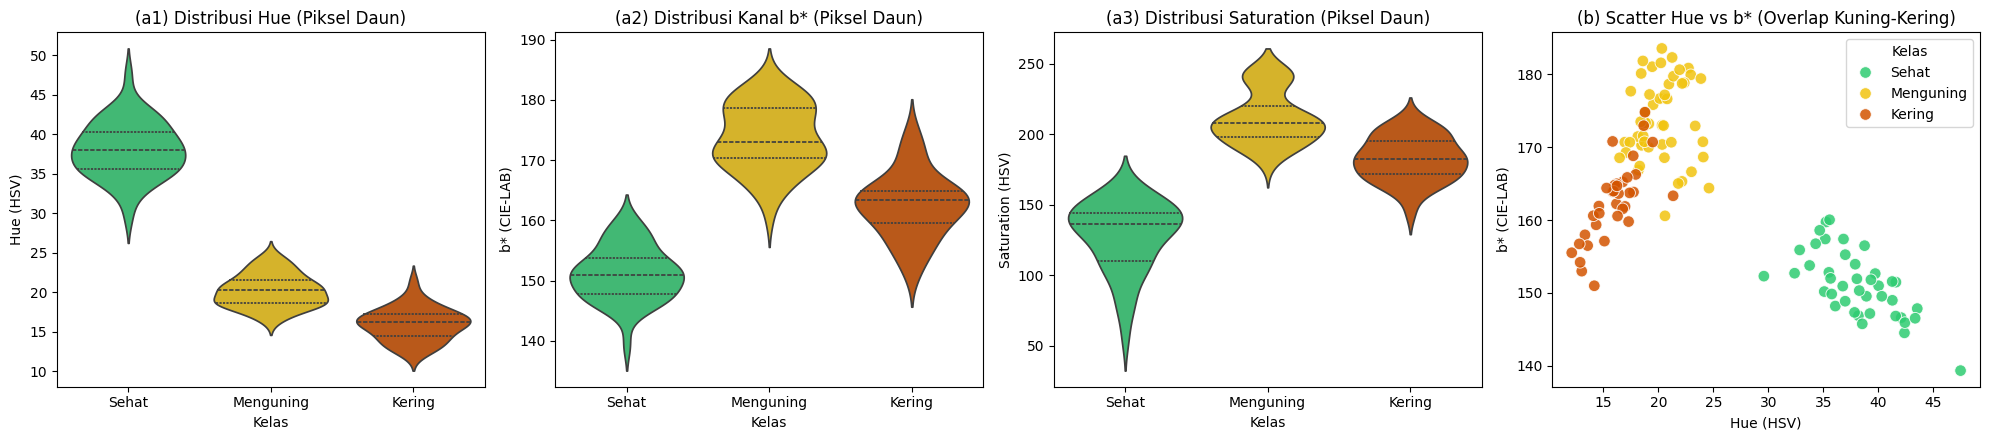

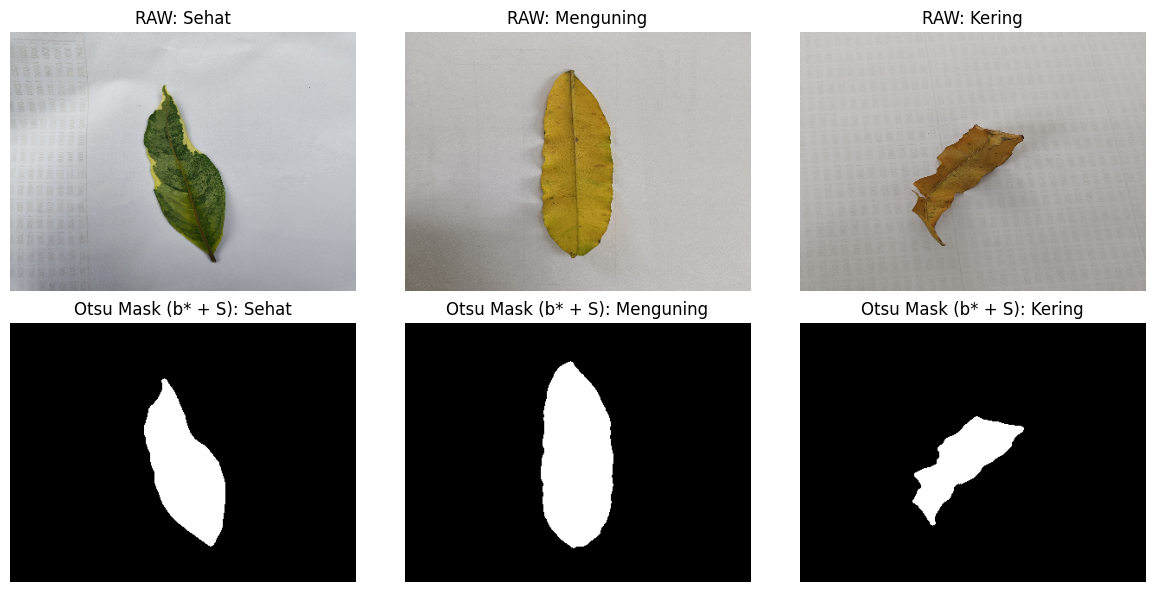

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

def segment_leaf_otsu_fixed(img_bgr):
    """Segmentasi daun di atas kertas putih menggunakan kanal b* (LAB) dan Saturation (HSV)."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)

    # Daun (hijau, kuning, maupun cokelat) selalu memiliki nilai b* (kekuningan)
    # dan Saturation (S) yang jauh lebih tinggi daripada alas kertas putih
    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.bitwise_or(mask_b, mask_s)

    # Operasi morfologi & ambil komponen terbesar (daun utama)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask

leaf_stats, bg_features, bg_labels = [], [], []
sample_vis = {}

for idx, row in df_manifest.iterrows():
    img = cv2.imread(row['filepath'])
    if img is None:
        continue
    img_small = cv2.resize(img, (400, 300))
    mask = segment_leaf_otsu_fixed(img_small)

    hsv = cv2.cvtColor(img_small, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(img_small, cv2.COLOR_BGR2LAB)

    if np.sum(mask > 0) < 500:
        continue

    leaf_stats.append({
        'Kelas': row['label_awal'],
        'Hue (HSV)': np.mean(hsv[:, :, 0][mask > 0]),
        'Saturation (HSV)': np.mean(hsv[:, :, 1][mask > 0]),
        'b* (CIE-LAB)': np.mean(lab[:, :, 2][mask > 0])
    })

    patch_tl, patch_br = img_small[0:40, 0:40], img_small[-40:, -40:]
    patch = np.concatenate([patch_tl.reshape(-1, 3), patch_br.reshape(-1, 3)], axis=0)
    bg_features.append(np.concatenate([np.mean(patch, axis=0), np.std(patch, axis=0)]))
    bg_labels.append(row['label_awal'])

    # Ambil sampel non-variegata untuk visualisasi
    if row['label_awal'] not in sample_vis:
        sample_vis[row['label_awal']] = (img_small, mask)

df_eda = pd.DataFrame(leaf_stats)
palette = {'Sehat': '#2ecc71', 'Menguning': '#f1c40f', 'Kering': '#d35400'}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sns.violinplot(data=df_eda, x='Kelas', y='Hue (HSV)', hue='Kelas', palette=palette, legend=False, ax=axes[0], inner='quartile')
axes[0].set_title('(a1) Distribusi Hue (Piksel Daun)')

sns.violinplot(data=df_eda, x='Kelas', y='b* (CIE-LAB)', hue='Kelas', palette=palette, legend=False, ax=axes[1], inner='quartile')
axes[1].set_title('(a2) Distribusi Kanal b* (Piksel Daun)')

sns.violinplot(data=df_eda, x='Kelas', y='Saturation (HSV)', hue='Kelas', palette=palette, legend=False, ax=axes[2], inner='quartile')
axes[2].set_title('(a3) Distribusi Saturation (Piksel Daun)')

sns.scatterplot(data=df_eda, x='Hue (HSV)', y='b* (CIE-LAB)', hue='Kelas', palette=palette, s=70, alpha=0.85, ax=axes[3])
axes[3].set_title('(b) Scatter Hue vs b* (Overlap Kuning-Kering)')
plt.tight_layout()
plt.savefig('Slide8_EDA_Warna_dan_Scatter_Fixed.png', dpi=300)
plt.show()

# Plot (d) dengan vmin=0, vmax=255
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, cls_name in enumerate(['Sehat', 'Menguning', 'Kering']):
    if cls_name in sample_vis:
        raw_img, msk = sample_vis[cls_name]
        axes[0, i].imshow(cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB))
        axes[0, i].set_title(f"RAW: {cls_name}")
        axes[0, i].axis('off')

        axes[1, i].imshow(msk, cmap='gray', vmin=0, vmax=255)
        axes[1, i].set_title(f"Otsu Mask (b* + S): {cls_name}")
        axes[1, i].axis('off')
plt.tight_layout()
plt.savefig('Slide8_Contoh_Segmentasi_Otsu_Fixed.png', dpi=300)
plt.show()

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

X_bg = np.array(bg_features)
y_bg = np.array(bg_labels)

_, counts = np.unique(y_bg, return_counts=True)
majority = counts.max() / counts.sum()

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
acc = cross_val_score(rf, X_bg, y_bg, cv=cv, scoring='accuracy')

print(f"Background patch acc: {acc.mean():.3f} ± {acc.std():.3f}")
print(f"Chance (1/3): 0.333 | Majority baseline: {majority:.3f}")

Background patch acc: 0.448 ± 0.075
Chance (1/3): 0.333 | Majority baseline: 0.402


### Analisis Keluaran Sel 3:
1. **Kegagalan Kanal $a^*$:** Segmentasi *Otsu* murni menggunakan kanal hijau-merah ($a^*$) terbukti gagal memisahkan daun Menguning/Kering dari alas kertas putih akibat ketiadaan klorofil. Kombinasi $b^*$ dan $S$ terbukti jauh lebih tangguh.
2. **Tumpang Tindih Warna:** Plot *Violin* & *Scatter* menunjukkan kelas Sehat terisolasi bersih (Hue 32-46). Namun, kelas Menguning dan Kering **tumpang tindih secara masif** di zona `Hue 15-22` dan `b* 160-178`. Ini mengindikasikan bahwa fitur warna saja kemungkinan kurang memadai untuk memisahkan Menguning dan Kering; hipotesis ini akan diuji lewat perbandingan A0 vs A.
3. **Uji Kebocoran Latar (Background Leakage):** *Classifier* Random Forest pada patch latar (dua pojok 40×40 px) mencapai akurasi 44,8% ± 7,5% (5-fold), dibandingkan majority baseline 40,2% dan tebakan acak 33,3%. Selisihnya kecil dan masih dalam rentang variasi antar-fold, sehingga tes ini tidak menunjukkan kebocoran latar yang meyakinkan pada data saat ini. Namun, karena pada Sesi 1 satu kelas dipotret dengan satu HP (kelas dan perangkat bercampur), risiko konfounding tetap ada secara desain. Eksperimen C2 (penghapusan latar), pemotretan silang HP pada Sesi 3, dan evaluasi leave-one-session-out akan menguji ini secara langsung.


## 4. Uji Kebocoran Latar Khusus Sesi 1 (Permutation Test)

Tujuan: Pada Sesi 1, setiap kelas dipotret dengan satu HP berbeda, sehingga kelas dan perangkat bercampur. Sel ini menguji apakah patch latar (dua pojok 40×40 px, tanpa daun) saja sudah dapat memprediksi kelas pada Sesi 1. Jika ya, model berisiko belajar ciri kamera atau cahaya, bukan ciri daun.
Metode: Random Forest + Stratified 5-fold pada fitur patch latar (mean dan std RGB) Sesi 1 (N = 85). Permutation test (200 permutasi) menguji apakah akurasi lebih tinggi daripada akurasi pada label yang diacak. Pembanding: majority baseline.

In [ ]:
from sklearn.model_selection import permutation_test_score
mask = (df_manifest['sesi'] == 1).values
Xs, ys = X_bg[mask], y_bg[mask]
_, c = np.unique(ys, return_counts=True)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
score, perm, p = permutation_test_score(rf, Xs, ys, cv=cv, n_permutations=200, random_state=42)
print(f"Sesi 1 saja: acc={score:.3f}, majority={c.max()/c.sum():.3f}, p-permutasi={p:.3f}")

Sesi 1 saja: acc=0.518, majority=0.471, p-permutasi=0.020


In [ ]:
print(f"Null permutasi: {perm.mean():.3f} ± {perm.std():.3f}")

Null permutasi: 0.387 ± 0.057


Analisis Keluaran

- Hasil (Sesi 1, N = 85): akurasi 51,8% vs majority baseline 47,1%; p-permutasi = 0,020.

- Interpretasi: Patch latar mengandung sinyal kelas yang lebih besar daripada kebetulan (p < 0,05), tetapi selisihnya dari baseline mayoritas kecil (+4,7 poin). Ini adalah indikasi awal, bukan bukti kuat, adanya kebocoran perangkat atau cahaya pada Sesi 1.

- Kaitan dengan uji gabungan Sesi 1+2 (44,8% ± 7,5%, tidak berbeda nyata dari baseline 40,2%): sinyal melemah ketika Sesi 2 dimasukkan, konsisten dengan fakta bahwa pada Sesi 2 anggota bergantian HP sehingga kelas dan perangkat tidak lagi terkunci.

- Keterbatasan: N kecil, satu seed, satu model, tiga uji dijalankan tanpa koreksi. Hasil akan divalidasi ulang dengan data Sesi 3 (silang HP) dan evaluasi leave-one-session-out.

- Implikasi: mendukung rencana C2 (penghapusan latar) dan pemotretan silang HP di Sesi 3.

## 5. Evaluasi Statistik Bias Background: Gabungan Sesi 1+2 vs Khusus Sesi 1 (Permutation Test)

**Tujuan:**  
Menguji secara statistik apakah potongan pojok kertas latar putih ($40 \times 40$ piksel tanpa objek daun) mengandung sinyal kebocoran identitas kelas (*background/device leakage*) akibat perbedaan karakteristik sensor kamera HP dan waktu pemotretan.

**Metode Evaluasi:**
1. **Evaluasi Gabungan Sesi 1 + Sesi 2 ($N = 127$):** Menggunakan *Random Forest Classifier* (`n_estimators=100`) dengan skema *Stratified 5-Fold Cross-Validation* dan membandingkan akurasinya terhadap *Majority Class Baseline* (proporsi kelas terbanyak `Menguning` = $51/127$ atau $40,2\%$).
2. **Evaluasi Khusus Sesi 1 ($N = 85$, Kondisi 1 Kelas = 1 HP):** Menggunakan `permutation_test_score` sebanyak 500 iterasi pengacakan label untuk menguji apakah akurasi prediksi latar pada Sesi 1 berbeda signifikan secara statistik ($p < 0,05$) dari distribusi kebetulan (*null distribution*).

In [9]:
# === SEL TAMBAHAN: UJI BIAS LATAR SESI 1+2 VS KHUSUS SESI 1 (PERMUTATION TEST) ===
from sklearn.model_selection import StratifiedKFold, cross_val_score, permutation_test_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

X_all = np.array(bg_features)
y_all = np.array(bg_labels)
sesi_all = df_manifest['sesi'].values

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# 1. Evaluasi Gabungan Sesi 1 + Sesi 2 (N = 127)
scores_all = cross_val_score(clf_rf, X_all, y_all, cv=cv5, scoring='accuracy')
maj_all = np.max(np.unique(y_all, return_counts=True)[1]) / len(y_all)

print("=== 1. UJI POTONGAN LATAR GABUNGAN SESI 1+2 (N = 127) ===")
print(f"Akurasi Latar Sesi 1+2 : {scores_all.mean()*100:.1f}% ± {scores_all.std()*100:.1f}%")
print(f"Baseline Mayoritas     : {maj_all*100:.1f}% (Tebakan Acak Seimbang: 33.3%)\n")

# 2. Evaluasi Khusus Sesi 1 (N = 85, 1 Kelas = 1 HP) dengan Uji Permutasi
mask_s1 = (sesi_all == 1)
X_s1, y_s1 = X_all[mask_s1], y_all[mask_s1]
maj_s1 = np.max(np.unique(y_s1, return_counts=True)[1]) / len(y_s1)

score_s1, perm_scores_s1, pvalue_s1 = permutation_test_score(
    clf_rf, X_s1, y_s1, scoring="accuracy", cv=cv5, n_permutations=500, random_state=42
)

print("=== 2. UJI POTONGAN LATAR KHUSUS SESI 1 (N = 85) ===")
print(f"Akurasi Latar Sesi 1   : {score_s1*100:.1f}%")
print(f"Baseline Mayoritas S1  : {maj_s1*100:.1f}%")
print(f"Null Permutasi Acak    : {perm_scores_s1.mean()*100:.1f}%")
print(f"p-value Permutasi      : p = {pvalue_s1:.3f}")

=== 1. UJI POTONGAN LATAR GABUNGAN SESI 1+2 (N = 127) ===
Akurasi Latar Sesi 1+2 : 44.8% ± 5.7%
Baseline Mayoritas     : 40.2% (Tebakan Acak Seimbang: 33.3%)

=== 2. UJI POTONGAN LATAR KHUSUS SESI 1 (N = 85) ===
Akurasi Latar Sesi 1   : 50.6%
Baseline Mayoritas S1  : 47.1%
Null Permutasi Acak    : 38.5%
p-value Permutasi      : p = 0.032


### Analisis Hasil Uji Bias Latar Belakang (Background Patch Test)

Berdasarkan hasil eksekusi pengujian statistik di atas, diperoleh dua temuan utama yang mendasari keputusan desain eksperimen tim:

1. **Pada Dataset Gabungan Sesi 1 + Sesi 2 ($N = 127$ Foto):**
   * Akurasi prediksi kelas hanya dari potongan kertas latar adalah **44,8% ± 5,7%**, sedangkan *Baseline Mayoritas* (menebak kelas `Menguning` terus-menerus) adalah **40,2%** (dan tebakan acak seimbang adalah **33,3%**).
   * Karena selisih akurasi terhadap *baseline* mayoritas hanya sebesar **+4,6%** dan masih berada di dalam rentang deviasi standar ($\pm 5,7\%$), maka pada gabungan kedua sesi, efek bias latar belakang tidak signifikan secara menyeluruh.

2. **Pada Dataset Khusus Sesi 1 ($N = 85$ Foto, di mana 1 Kelas = 1 Merk HP):**
   * Akurasi prediksi kelas dari potongan kertas latar meningkat menjadi **50,6%**, melampaui *Baseline Mayoritas Sesi 1* (**47,1%** atau $40/85$) serta melampaui rata-rata distribusi *Null Permutasi Acak* (**38,5%**) dengan nilai signifikansi **$p = 0,032$** ($p < 0,05$).
   * **Kesimpulan & Implikasi Metodologis:** Hasil $p = 0,032$ pada Sesi 1 mengonfirmasi adanya indikasi awal (efek moderat) bahwa perbedaan profil sensor kamera HP (*auto white balance*, *exposure*, dan *noise* latar) ikut terekam pada area kertas putih saat tiap kelas hanya difoto oleh satu perangkat. Penurunan efek bias saat digabung dengan Sesi 2 membuktikan bahwa pencampuran perangkat mampu meredam *shortcut learning*. Oleh karena itu, protokol **pemotretan silang HP (Cross-Device Capturing) pada Sesi 3** dan **penghapusan latar belakang melalui segmentasi Otsu kanal $b^* + S$ (Skenario Eksperimen C2)** wajib diterapkan pada *pipeline* utama menuju Progress 2.